## **Task: Build an index using annoy and nsw. Compare the performance using one of the metrics you prefer.**

# Lab 10 — Indexing with Graphs

**Approximate Nearest Neighbour (ANN) search with graph indexes: proximity graphs, NSW and HNSW**

## Where we are
In **Lab 09 (Indexing with Trees)** we indexed vectors by *partitioning* the space (KD-tree, Ball tree, VP-tree) and pruned branches with a geometric bound. The scalability ended with the key problem:

* a KD-tree examined **0.3 %** of the points in 2-D, **75 %** at 10 dimensions and **100 %** from 20 dimensions on. In high dimension nothing can be pruned, and exact trees become brute force with overhead.
* Annoy stayed fast by being approximate, but its recall@100 fell to **0.22** (20 trees) at 200 dimensions.

Text embeddings have hundreds of dimensions. Graph indexes take a different route. Instead of cutting the space into regions, they **link every vector to nearby vectors and walk along the links** towards the query. This lab shows how, and measures how well it works.

In [1]:
!uv tree -d 1

Resolved 222 packages in 7ms
ir v0.1.0
├── altair v6.2.2
├── annoy v1.17.3
├── beautifulsoup4 v4.15.0
├── bs4 v0.0.2
├── feedparser v6.0.14
├── ipykernel v7.3.0
├── matplotlib v3.10.9
├── nltk v3.10.3
├── pandas v2.3.3
├── requests v2.34.2
├── scikit-learn v1.7.2
├── selenium v4.48.0
├── sentence-transformers v6.2.0
└── statsmodels v0.15.0


In [2]:
# Worked example 1.1 — cosine similarity "by hand" with NumPy
import numpy as np

def cosine(u, v):
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))

q, a, b = np.array([1, 2]), np.array([2, 4]), np.array([3, -1])
print("cos(q, a) =", round(cosine(q, a), 4))   # 1.0   (same direction)
print("cos(q, b) =", round(cosine(q, b), 4))   # ~0.1414 (almost orthogonal)

cos(q, a) = 1.0
cos(q, b) = 0.1414


## 1.2 Exact search (brute force / "flat" index) and why it does not scale
The exact method compares the query with **every** vector and keeps the top $k$:

$$\text{cost per query}=O(n\cdot d).$$

*Example.* $n=10^8$ documents with $d=300$ floats means $3\times10^{10}$ multiplications **per query**, and 120 GB of RAM just for the vectors (float32). With hundreds of queries per second this is infeasible.

**Curse of dimensionality (recap of Lab 09).** Tree-based indexes (k-d trees, ball trees) work well for $d\lesssim 10$, but in hundreds of dimensions distances between random points concentrate (the nearest and farthest neighbours become almost equally far), pruning stops working, and trees degrade to brute force. In Lab 09 our KD-tree examined 75 % of the points at $d=10$ and all of them from $d=20$. The next demo recalls why.

In [3]:
# distance concentration: (max - min) / min of distances to a random query
rng = np.random.default_rng(0)
print(f"{'dim':>6} | (farthest - nearest) / nearest")
for d in [2, 10, 50, 300, 1000]:
    X = rng.random((5000, d)); q = rng.random(d)
    dist = np.linalg.norm(X - q, axis=1)
    print(f"{d:>6} | {(dist.max() - dist.min()) / dist.min():.3f}")
# The ratio shrinks quickly: in high dimension "near" and "far" are hard to tell apart,
# so space-partitioning trees cannot discard large regions of the space.

   dim | (farthest - nearest) / nearest
     2 | 663.257
    10 | 3.400
    50 | 0.778
   300 | 0.230
  1000 | 0.139


## 1.3 Approximate Nearest Neighbour (ANN) search
ANN accepts that the returned list may miss a few true neighbours in exchange for orders-of-magnitude faster queries. Graph indexes are currently the best performers in the speed/recall trade-off for in-memory search and are used by most vector databases.

### Quality: recall@N
We compare the ANN result with the exact result (the **ground truth**). For one query,

$$\text{recall@}N=\frac{\lvert \text{ANN}_N\cap \text{Exact}_N\rvert}{N},$$

where $\text{ANN}_N$ / $\text{Exact}_N$ are the first $N$ results of each method. Average over many queries.

*Worked example.* Exact top-5 = $\{7,3,9,1,4\}$, ANN top-5 = $\{7,3,2,1,8\}$. Common items: $\{7,3,1\}$ → recall@5 $=3/5=0.6$.

In [4]:
# Worked example 1.3 — recall@N for one query
def recall_example(approx, exact, N):
    return len(set(approx[:N]) & set(exact[:N])) / N

exact  = [7, 3, 9, 1, 4]
approx = [7, 3, 2, 1, 8]
print("recall@5 =", recall_example(approx, exact, 5))   # 0.6
print("recall@2 =", recall_example(approx, exact, 2))   # 1.0 (7 and 3 are right)

recall@5 = 0.6
recall@2 = 1.0


## 1.4 Worked example: the Lab 09 points as a graph
We reuse the 8 points and the query of Lab 09, so the two labs can be compared directly:

A(1,9), B(3,6), C(6,8), D(9,7), E(7,4), F(2,3), G(4,2), H(8,5), query **q = (2,7)**, **k = 2**. True answer: **B (1.41), A (2.24)**.

The next cell contains a small library that we use. It follows the HNSW paper (Malkov & Yashunin, 2018) closely:

| Function / class | What it does | Paper |
|---|---|---|
| `search_layer(X, adj, q, entries, ef)` | beam search: keeps the `ef` best nodes in **W**, expands candidates **C** closest-first, stops when the closest candidate is worse than the worst result | Algorithm 2 |
| `build_knn_graph(X, M)` | links each point to its `M` nearest points (both directions) | — |
| `greedy_route(X, adj, q, entry)` | plain greedy routing: move to the closest neighbour until none is closer | — |
| `NSW` | inserts points one by one; each new point links to the `M` nearest nodes found by `search_layer` with `ef_construction` | Malkov et al. 2014 |
| `HNSW` | random levels, greedy descent through upper layers, `efConstruction` search per layer, `M` links (2M on layer 0), shrinking overfull lists, optional *heuristic* neighbour selection | Algorithms 1, 3, 4, 5 |

Every function accepts `log=[]` (a list that receives one readable line per step) and `name=` (how to print a node), which is what makes the traces below possible.

In [5]:
# Part 1 graph library: pure NumPy, written for reading, not for speed
import matplotlib.pyplot as plt
import time
import heapq, math
import numpy as np


def l2(a, b):
    return float(np.linalg.norm(np.asarray(a, float) - np.asarray(b, float)))


def search_layer(X, adj, q, entries, ef, stats=None, log=None, name=str):
    """SEARCH-LAYER (Malkov & Yashunin 2018, Algorithm 2): beam search that keeps the ef best nodes.

    X       : array (n, d) with the vectors
    adj     : dict  node -> list of neighbours (one layer of the graph)
    entries : list of entry nodes
    stats   : optional dict; stats["dist"] counts distance computations
    log     : optional list; one line of explanation is appended per step
    Returns the (at most) ef best nodes as a list of (distance, node), closest first."""
    def d(i):
        if stats is not None: stats["dist"] = stats.get("dist", 0) + 1
        return l2(X[i], q)
    visited = set(entries)
    C, W = [], []                                # C: candidates, min-heap. W: results, max-heap (-dist)
    for e in entries:
        de = d(e)
        heapq.heappush(C, (de, e)); heapq.heappush(W, (-de, e))
    while len(W) > ef:
        heapq.heappop(W)
    fmtW = lambda: "[" + ", ".join(f"{name(b)} {-a:.2f}" for a, b in sorted(W, reverse=True)) + "]"
    if log is not None:
        log.append(f"start at {', '.join(name(e) for e in entries)} -> C = W = {fmtW()}")
    while C:
        dc, c = heapq.heappop(C)                 # the closest candidate not expanded yet
        worst = -W[0][0]
        if dc > worst:                           # it is worse than every result: nothing better is reachable
            if log is not None:
                log.append(f"pop {name(c)} ({dc:.2f}) > worst in W ({worst:.2f}) -> STOP")
            break
        notes = []
        for e in adj.get(c, []):
            if e in visited:
                continue
            visited.add(e)
            de = d(e)
            worst = -W[0][0]
            if de < worst or len(W) < ef:
                heapq.heappush(C, (de, e)); heapq.heappush(W, (-de, e))
                if len(W) > ef:
                    heapq.heappop(W)
                notes.append(f"{name(e)} {de:.2f} keep")
            else:
                notes.append(f"{name(e)} {de:.2f} drop")
        if log is not None:
            log.append(f"expand {name(c)} ({dc:.2f}): " + (", ".join(notes) or "no unvisited neighbours")
                       + f"  ->  W = {fmtW()}")
    return sorted((-a, b) for a, b in W)


def build_knn_graph(X, M):
    """Each node is linked to its M nearest nodes; links are made bidirectional."""
    X = np.asarray(X, float)
    D = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    np.fill_diagonal(D, np.inf)
    adj = {i: set() for i in range(len(X))}
    for i in range(len(X)):
        for j in np.argsort(D[i], kind="stable")[:M]:
            adj[i].add(int(j)); adj[int(j)].add(i)
    return {i: sorted(s) for i, s in adj.items()}


def greedy_route(X, adj, q, entry, stats=None, log=None, name=str):
    """Plain greedy routing: move to the neighbour closest to q until no neighbour is closer."""
    def d(i):
        if stats is not None: stats["dist"] = stats.get("dist", 0) + 1
        return l2(X[i], q)
    cur, cur_d = entry, d(entry)
    path = [cur]
    if log is not None: log.append(f"start at {name(cur)}: d = {cur_d:.2f}")
    while True:
        best, best_d, notes = cur, cur_d, []
        for nb in adj[cur]:
            dn = d(nb); notes.append(f"{name(nb)} {dn:.2f}")
            if dn < best_d:
                best, best_d = nb, dn
        if best == cur:
            if log is not None: log.append(f"at {name(cur)}: neighbours " + ", ".join(notes) + " -> none closer: STOP (local minimum)")
            return cur, cur_d, path
        if log is not None: log.append(f"at {name(cur)}: neighbours " + ", ".join(notes) + f" -> move to {name(best)}")
        cur, cur_d = best, best_d
        path.append(cur)


class NSW:
    """Navigable Small World graph (Malkov et al. 2014), one layer.
    Points are inserted one by one; each new point is linked (both ways) to the M nearest nodes
    that a beam search with ef_construction finds in the graph built so far. No degree limit."""

    def __init__(self, M=2, ef_construction=4):
        self.M, self.efc = M, ef_construction
        self.adj, self.order, self.entry = {}, [], None

    def insert(self, i, log=None, name=str):
        if self.entry is None:
            self.adj[i], self.entry = [], i
            self.order.append(i)
            if log is not None: log.append(f"insert {name(i)}: first point, becomes the entry point")
            return
        W = search_layer(self.X, self.adj, self.X[i], [self.entry], self.efc)
        nbrs = [b for _, b in W[:self.M]]
        self.adj[i] = list(nbrs)
        for b in nbrs:
            self.adj[b].append(i)
        self.order.append(i)
        if log is not None:
            log.append(f"insert {name(i)}: search found " + ", ".join(f"{name(b)} {a:.2f}" for a, b in W)
                       + f" -> link to {', '.join(name(b) for b in nbrs)}")

    def build(self, X, order=None, log=None, name=str):
        self.X = np.asarray(X, float)
        for i in (range(len(self.X)) if order is None else order):
            self.insert(int(i), log, name)
        return self

    def search(self, q, k, ef, log=None, name=str):
        stats = {}
        W = search_layer(self.X, self.adj, np.asarray(q, float), [self.entry], max(ef, k), stats, log, name)
        return [b for _, b in W[:k]], [a for a, _ in W[:k]], stats["dist"]


class HNSW:
    """Hierarchical NSW (Malkov & Yashunin 2018), written for teaching, following the paper:
    Algorithm 1 (INSERT), 2 (SEARCH-LAYER), 3 (simple neighbour selection),
    4 (heuristic selection, optional) and 5 (K-NN-SEARCH).
    M       : links per node on layers >= 1 (layer 0 allows 2*M)
    mL      : level normalisation, default 1 / ln(M)"""

    def __init__(self, M=4, ef_construction=16, mL=None, seed=0, heuristic=False, levels=None):
        self.M, self.M0, self.efc = M, 2 * M, ef_construction
        self.mL = mL if mL is not None else 1 / math.log(max(M, 2))
        self.rng = np.random.default_rng(seed)
        self.heuristic = heuristic
        self.fixed_levels = levels          # optional: given levels instead of random ones (for worked examples)
        self.layers = []                    # layers[l] = dict node -> list of neighbours
        self.level = {}                     # node -> its top layer
        self.entry, self.top = None, -1

    def _draw_level(self):
        return int(math.floor(-math.log(1.0 - self.rng.random()) * self.mL))

    def _select(self, base, cands, m):
        """cands: list of (distance to base, node), any order. Returns at most m nodes."""
        cands = sorted(cands)
        if not self.heuristic:
            return [b for _, b in cands[:m]]            # Algorithm 3: the m closest
        out = []                                         # Algorithm 4: keep e only if it is closer to base
        for de, e in cands:                              # than to every neighbour already kept (diversity)
            if len(out) >= m: break
            if all(de < l2(self.X[e], self.X[r]) for r in out):
                out.append(e)
        return out

    def insert(self, i, log=None, name=str):
        X, q = self.X, self.X[i]
        lvl = self._draw_level() if self.fixed_levels is None else int(self.fixed_levels[i])
        self.level[i] = lvl
        while len(self.layers) <= lvl:
            self.layers.append({})
        for l in range(lvl + 1):
            self.layers[l][i] = []
        if self.entry is None:
            self.entry, self.top = i, lvl
            if log is not None: log.append(f"insert {name(i)}: level {lvl}, first point -> global entry point")
            return
        ep = [self.entry]
        for l in range(self.top, lvl, -1):                       # 1) greedy descent above the new level
            ep = [search_layer(X, self.layers[l], q, ep, 1)[0][1]]
        msgs = []
        for l in range(min(self.top, lvl), -1, -1):              # 2) connect on every layer <= lvl
            W = search_layer(X, self.layers[l], q, ep, self.efc)
            mmax = self.M0 if l == 0 else self.M
            nbrs = self._select(i, W, self.M)
            self.layers[l][i] = list(nbrs)
            msgs.append(f"L{l}: link to {', '.join(name(b) for b in nbrs)}")
            for e in nbrs:
                self.layers[l][e].append(i)
                if len(self.layers[l][e]) > mmax:                 # 3) shrink an overfull neighbour list
                    old = self.layers[l][e]
                    self.layers[l][e] = self._select(e, [(l2(X[e], X[c]), c) for c in old], mmax)
                    dropped = set(old) - set(self.layers[l][e])
                    msgs.append(f"L{l}: {name(e)} has {len(old)} > {mmax} links, drops {', '.join(name(c) for c in dropped)}")
            ep = [b for _, b in W]
        if lvl > self.top:
            self.entry, self.top = i, lvl
            msgs.append("new top level -> becomes the global entry point")
        if log is not None: log.append(f"insert {name(i)}: level {lvl}; " + "; ".join(msgs))

    def build(self, X, order=None, log=None, name=str):
        self.X = np.asarray(X, float)
        for i in (range(len(self.X)) if order is None else order):
            self.insert(int(i), log, name)
        return self

    def search(self, q, k, ef, log=None, name=str):
        q, stats, ep = np.asarray(q, float), {}, [self.entry]
        for l in range(self.top, 0, -1):                          # greedy (ef = 1) on the upper layers
            sub = [] if log is not None else None
            ep = [search_layer(self.X, self.layers[l], q, ep, 1, stats, sub, name)[0][1]]
            if log is not None: log += [f"[layer {l}] " + s for s in sub]
        sub = [] if log is not None else None
        W = search_layer(self.X, self.layers[0], q, ep, max(ef, k), stats, sub, name)
        if log is not None: log += ["[layer 0] " + s for s in sub]
        return [b for _, b in W[:k]], [a for a, _ in W[:k]], stats["dist"]

In [6]:
P8 = np.array([[1, 9], [3, 6], [6, 8], [9, 7], [7, 4], [2, 3], [4, 2], [8, 5]], dtype=float)
q8 = np.array([2.0, 7.0])
NAMES8 = "ABCDEFGH"
nm8 = lambda i: NAMES8[i]
show_adj = lambda adj: "  ".join(f"{nm8(i)}:{''.join(nm8(j) for j in v)}" for i, v in sorted(adj.items()))

print("true distances:", ", ".join(f"{nm8(i)} {d:.2f}" for d, i in sorted((l2(p, q8), i) for i, p in enumerate(P8))))

# (a) a 2-NN proximity graph and greedy routing from two different entry points
G8 = build_knn_graph(P8, M=2)
print("\n2-NN graph:", show_adj(G8))
for entry in [3, 4]:                       # start at D, then at E
    log, st = [], {}
    node, d, path = greedy_route(P8, G8, q8, entry, st, log, nm8)
    print(f"\ngreedy from {nm8(entry)}:"); print("\n".join("   " + s for s in log))
    print(f"   -> {nm8(node)} ({d:.2f}), path {'-'.join(map(nm8, path))}, {st['dist']} distance computations")

# (b) beam search with ef = 3 from D: returns the top-k, not only one point
log, st = [], {}
W = search_layer(P8, G8, q8, [3], ef=3, stats=st, log=log, name=nm8)
print("\nbeam search, ef = 3, from D:"); print("\n".join("   " + s for s in log))
print("   top-2:", [(nm8(i), round(d, 2)) for d, i in W[:2]], f"| {st['dist']} distance computations")

true distances: B 1.41, A 2.24, F 4.00, C 4.12, G 5.39, E 5.83, H 6.32, D 7.00

2-NN graph: A:BC  B:ACF  C:ABD  D:CEH  E:DGH  F:BG  G:EF  H:DE

greedy from D:
   start at D: d = 7.00
   at D: neighbours C 4.12, E 5.83, H 6.32 -> move to C
   at C: neighbours A 2.24, B 1.41, D 7.00 -> move to B
   at B: neighbours A 2.24, C 4.12, F 4.00 -> none closer: STOP (local minimum)
   -> B (1.41), path D-C-B, 10 distance computations

greedy from E:
   start at E: d = 5.83
   at E: neighbours D 7.00, G 5.39, H 6.32 -> move to G
   at G: neighbours E 5.83, F 4.00 -> move to F
   at F: neighbours B 1.41, G 5.39 -> move to B
   at B: neighbours A 2.24, C 4.12, F 4.00 -> none closer: STOP (local minimum)
   -> B (1.41), path E-G-F-B, 11 distance computations

beam search, ef = 3, from D:
   start at D -> C = W = [D 7.00]
   expand D (7.00): C 4.12 keep, E 5.83 keep, H 6.32 keep  ->  W = [C 4.12, E 5.83, H 6.32]
   expand C (4.12): A 2.24 keep, B 1.41 keep  ->  W = [B 1.41, A 2.24, C 4.12]
   expand 

**Read the traces.**
* **Greedy** keeps a single current node and moves to its closest neighbour: from D it goes D → C → B and stops, because no neighbour of B is closer to q. Here the local minimum happens to be the true nearest neighbour; in larger graphs it often is not.
* **Beam search** keeps two lists: the candidates **C** (still to expand, closest first) and the results **W** (the best `ef` nodes so far). A neighbour is kept only if it beats the worst node of W (or W is not full yet). The search stops when the closest candidate is already worse than the worst result. It returns the top-k directly: B, A.

Now build the same 8 points as an **NSW** (inserted in the order A, B, …, H) and as an **HNSW**. For the HNSW we fix the levels instead of drawing them at random, so the example is reproducible: D reaches layer 2, E and F reach layer 1, all others stay on layer 0. (These are the levels the animator draws with its default seed 52.)

In [7]:
# (c) NSW: incremental insertion
log = []
nsw8 = NSW(M=2, ef_construction=3).build(P8, log=log, name=nm8)
print("NSW build:"); print("\n".join("   " + s for s in log))
print("NSW graph:", show_adj(nsw8.adj))
log = []
ids, dists, ndist = nsw8.search(q8, k=2, ef=3, log=log, name=nm8)
print("\nNSW search, ef = 3, from the entry point A:"); print("\n".join("   " + s for s in log))
print("   top-2:", [(nm8(i), round(d, 2)) for i, d in zip(ids, dists)], f"| {ndist} distance computations")

# (d) HNSW with fixed levels A0 B0 C0 D2 E1 F1 G0 H0
log = []
hnsw8 = HNSW(M=2, ef_construction=3, levels=[0, 0, 0, 2, 1, 1, 0, 0]).build(P8, log=log, name=nm8)
print("\nHNSW build:"); print("\n".join("   " + s for s in log))
for l, layer in reversed(list(enumerate(hnsw8.layers))):
    print(f"   layer {l}:", show_adj(layer))
log = []
ids, dists, ndist = hnsw8.search(q8, k=2, ef=3, log=log, name=nm8)
print("\nHNSW search (ef = 1 on layers 2 and 1, ef = 3 on layer 0):"); print("\n".join("   " + s for s in log))
print("   top-2:", [(nm8(i), round(d, 2)) for i, d in zip(ids, dists)], f"| {ndist} distance computations")

NSW build:
   insert A: first point, becomes the entry point
   insert B: search found A 3.61 -> link to A
   insert C: search found B 3.61, A 5.10 -> link to B, A
   insert D: search found C 3.16, B 6.08, A 8.25 -> link to C, B
   insert E: search found D 3.61, C 4.12, B 4.47 -> link to D, C
   insert F: search found B 3.16, E 5.10, A 6.08 -> link to B, E
   insert G: search found F 2.24, E 3.61, B 4.12 -> link to F, E
   insert H: search found E 1.41, D 2.24, C 3.61 -> link to E, D
NSW graph: A:BC  B:ACDF  C:BADE  D:CBEH  E:DCFGH  F:BEG  G:FE  H:ED

NSW search, ef = 3, from the entry point A:
   start at A -> C = W = [A 2.24]
   expand A (2.24): B 1.41 keep, C 4.12 keep  ->  W = [B 1.41, A 2.24, C 4.12]
   expand B (1.41): D 7.00 drop, F 4.00 keep  ->  W = [B 1.41, A 2.24, F 4.00]
   expand F (4.00): E 5.83 drop, G 5.39 drop  ->  W = [B 1.41, A 2.24, F 4.00]
   pop C (4.12) > worst in W (4.00) -> STOP
   top-2: [('B', 1.41), ('A', 2.24)] | 7 distance computations

HNSW build:
   inse

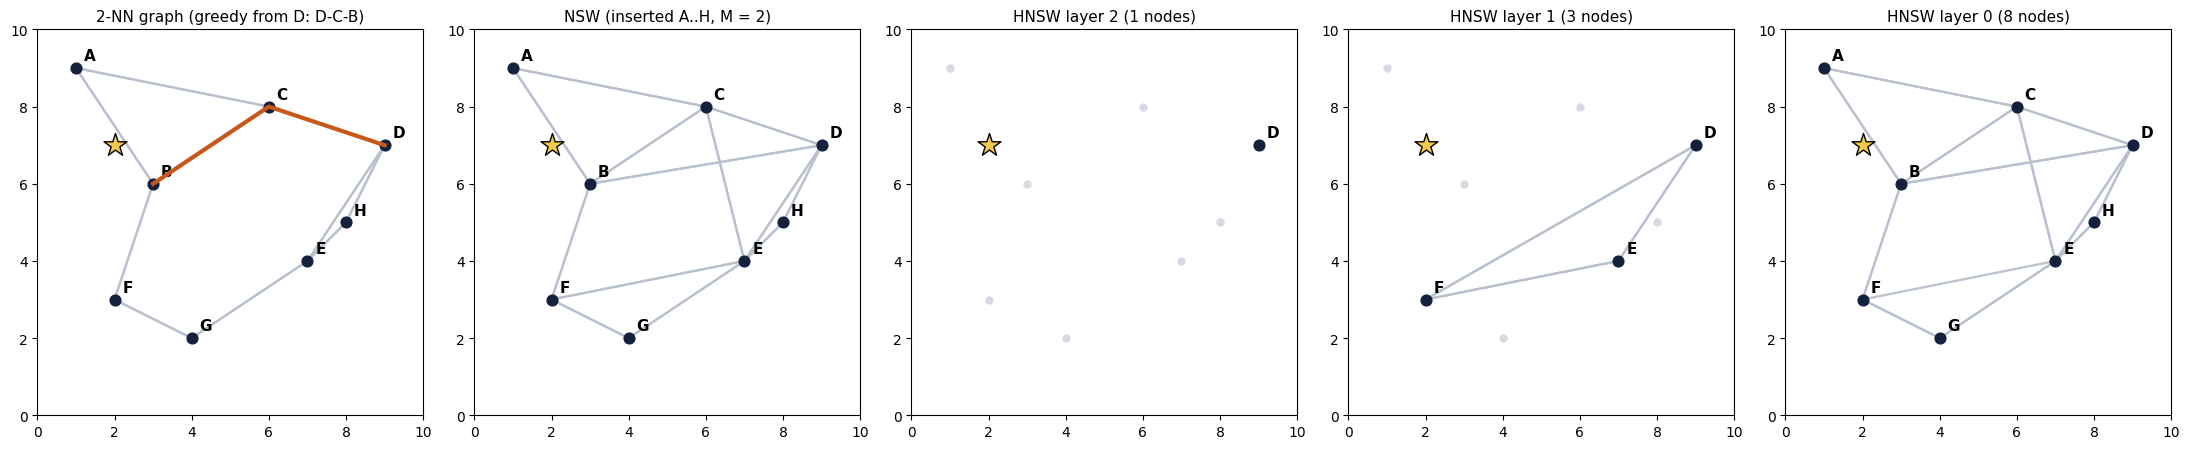

In [8]:
# Draw the three graphs and the HNSW layers
def draw_graph(ax, X, adj, title, nodes=None, q=None, path=None, names=NAMES8):
    nodes = list(adj) if nodes is None else nodes
    for a in adj:
        for b in adj[a]:
            ax.plot(*X[[a, b]].T, c="#B9C1CE", lw=1.6, zorder=1)
    other = [i for i in range(len(X)) if i not in nodes]
    ax.scatter(*X[other].T, s=25, c="#D5DAE3", zorder=2) if other else None
    ax.scatter(*X[nodes].T, s=60, c="#14213D", zorder=3)
    for i in nodes:
        ax.text(X[i, 0] + .2, X[i, 1] + .2, names[i], fontsize=11, fontweight="bold")
    if path is not None and len(path) > 1:
        ax.plot(*X[path].T, c="#C8571B", lw=3, zorder=4)
    if q is not None:
        ax.scatter(*q, marker="*", s=300, c="#F2C94C", edgecolor="k", zorder=5)
    ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect("equal"); ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8))
draw_graph(axes[0], P8, G8, "2-NN graph (greedy from D: D-C-B)", q=q8, path=[3, 2, 1])
draw_graph(axes[1], P8, nsw8.adj, "NSW (inserted A..H, M = 2)", q=q8)
for ax, l in zip(axes[2:], [2, 1, 0]):
    draw_graph(ax, P8, hnsw8.layers[l], f"HNSW layer {l} ({len(hnsw8.layers[l])} nodes)", nodes=list(hnsw8.layers[l]), q=q8)
plt.tight_layout(); plt.show()

**What to notice**
* **NSW:** each point got exactly `M = 2` links when it was inserted, but later points add links to it, and nothing limits that: at the end E has 5 links and B, C, D have 4, while G and H keep 2. At scale (1.6) the earliest nodes collect long links, which become the "highways", and many of them, which makes them hubs.
* **HNSW build:** when H is inserted, E would have 5 links on layer 0, more than `2M = 4`, so E keeps its 4 closest and drops F. Real HNSW limits the degree this way; plain NSW does not.
* **HNSW search:** it starts at the top (D), takes one greedy step on layer 1 to F, then searches layer 0 from F with `ef = 3`: it reaches B and A after **11** distance computations. On 8 points this saves nothing (brute force needs 8); the savings appear when $n$ is large (1.8 and Part 5).

## 1.5 Proximity graphs and greedy search at scale
Build a graph whose **nodes are the vectors** and where each node is linked to some of its near neighbours. To answer a query $q$:

1. Start at an **entry point** (any node).
2. Look at the neighbours of the current node; move to the one **closest to $q$**.
3. Repeat until no neighbour is closer than the current node (a *local minimum*) and return it.

This is **greedy search**. It touches only a tiny part of the graph — typically $O(\log n)$ to $O(\text{polylog } n)$ distance computations — instead of all $n$.

**Weakness 1 — local minima.** Greedy search can get stuck in a node that is better than all its neighbours but is not the global best. Fix: keep a *candidate list* of size `ef` instead of a single node (beam search, see 1.7).

**Weakness 2 — long paths.** If links are only short, many hops are needed to cross the space from a bad entry point. Fix: add some **long-range links** (small-world property, 1.6) or use **hierarchy** (1.8).

Run the demo below: it builds a $k$-NN graph on 2-D points (so we can draw it), performs greedy search, and measures how often greedy search finds the true nearest neighbour.

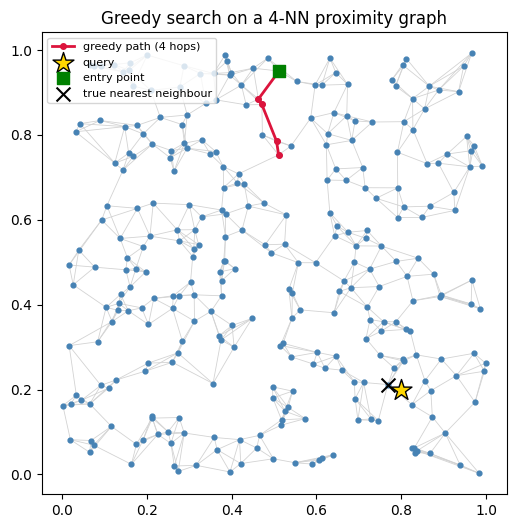

found node 23, true NN 41, distance computations: 23 (brute force: 300)


In [9]:
import matplotlib.pyplot as plt

def knn_graph(X, k):
    # adjacency list; each node linked to its k nearest nodes (brute force, only for a toy example)
    d = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    np.fill_diagonal(d, np.inf)
    nbrs = np.argsort(d, axis=1)[:, :k]
    # make links bidirectional, as NSW/HNSW do
    adj = [set(r) for r in nbrs.tolist()]
    for i, r in enumerate(nbrs):
        for j in r:
            adj[j].add(i)
    return [sorted(s) for s in adj]

def greedy_search(adj, X, q, entry):
    cur = entry
    cur_d = np.linalg.norm(X[cur] - q)
    path, ndist = [cur], 1
    while True:
        best, best_d = cur, cur_d
        for nb in adj[cur]:
            dd = np.linalg.norm(X[nb] - q); ndist += 1
            if dd < best_d:
                best, best_d = nb, dd
        if best == cur:                  # local minimum reached
            return cur, path, ndist
        cur, cur_d = best, best_d
        path.append(cur)

rng = np.random.default_rng(1)
X = rng.random((300, 2))
adj = knn_graph(X, k=4)
q = np.array([0.8, 0.2])
entry = 0
found, path, ndist = greedy_search(adj, X, q, entry)
true_nn = int(np.argmin(np.linalg.norm(X - q, axis=1)))

fig, ax = plt.subplots(figsize=(6, 6))
for i, nb in enumerate(adj):
    for j in nb:
        if i < j: ax.plot(*X[[i, j]].T, c="lightgray", lw=0.6, zorder=1)
ax.scatter(*X.T, s=12, c="steelblue", zorder=2)
ax.plot(*X[path].T, c="crimson", lw=2, marker="o", ms=4, zorder=3, label=f"greedy path ({len(path)-1} hops)")
ax.scatter(*q, marker="*", s=250, c="gold", edgecolor="k", zorder=4, label="query")
ax.scatter(*X[entry], marker="s", s=80, c="green", zorder=4, label="entry point")
ax.scatter(*X[true_nn], marker="x", s=100, c="black", zorder=5, label="true nearest neighbour")
ax.legend(loc="upper left", fontsize=8); ax.set_title("Greedy search on a 4-NN proximity graph"); plt.show()
print(f"found node {found}, true NN {true_nn}, distance computations: {ndist} (brute force: {len(X)})")

In [10]:
# How often does plain greedy search find the exact NN, from a random entry point?
rng = np.random.default_rng(2)
queries = rng.random((300, 2))
hits, cost = 0, 0
for q in queries:
    found, _, nd = greedy_search(adj, X, q, int(rng.integers(len(X))))
    hits += found == int(np.argmin(np.linalg.norm(X - q, axis=1))); cost += nd
print(f"greedy 1-NN accuracy: {hits/len(queries):.2f}   avg distance computations: {cost/len(queries):.1f} / {len(X)}")

greedy 1-NN accuracy: 0.27   avg distance computations: 32.9 / 300


## 1.6 Navigable Small World (NSW)
A graph is a **small world** if (a) it is locally clustered and (b) any two nodes are connected by a **short path** ($O(\log n)$ hops) thanks to a few long-range links (think of "six degrees of separation").

**NSW construction (Malkov et al. 2014):** insert the points one by one, in random order.
1. For a new point $x$, run the search on the current graph to find its $M$ (approximately) nearest existing nodes.
2. Connect $x$ bidirectionally to these $M$ nodes.

Because early points were inserted when the graph was small, their links are *long* (their nearest neighbours at that time were far away). Later points get *short* links. This gives the mix of long and short edges needed for fast navigation **without** any global computation.

*Problem:* with many points the search can still need many hops and the hubs created by early nodes become a bottleneck → search cost grows polylogarithmically with a big constant. HNSW fixes this with layers.

## 1.7 Beam search with `ef`
Instead of following a single best neighbour, keep a **priority queue of the `ef` best candidates** found so far:

```
candidates = {entry};  results = {entry}            # results holds at most ef nodes
while candidates not empty:
    c = closest node in candidates
    if dist(c, q) > dist(worst node in results, q) and |results| == ef:   break
    for each neighbour n of c not yet visited:
        if dist(n, q) < dist(worst in results, q) or |results| < ef:
            add n to candidates and results; drop the worst of results if |results| > ef
return the k best of results
```
Larger `ef` ⇒ explores more of the graph ⇒ higher recall but slower queries. It must satisfy `ef ≥ k`.

In [11]:
import heapq

def beam_search(adj, X, q, entry, ef):
    # ef-beam search (the 'search_layer' routine of HNSW). Returns (sorted ids, number of distance computations).
    dist = lambda i: float(np.linalg.norm(X[i] - q))
    d0 = dist(entry); ndist = 1
    visited = {entry}
    cand = [(d0, entry)]            # min-heap (closest first)
    res = [(-d0, entry)]            # max-heap via negative distance (worst first)
    while cand:
        dc, c = heapq.heappop(cand)
        if len(res) >= ef and dc > -res[0][0]:
            break
        for nb in adj[c]:
            if nb in visited: continue
            visited.add(nb); dn = dist(nb); ndist += 1
            if len(res) < ef or dn < -res[0][0]:
                heapq.heappush(cand, (dn, nb)); heapq.heappush(res, (-dn, nb))
                if len(res) > ef: heapq.heappop(res)
    return [i for _, i in sorted([(-d, i) for d, i in res])], ndist

rng = np.random.default_rng(3)
queries = rng.random((300, 2)); true = [np.argsort(np.linalg.norm(X - q, axis=1))[:10] for q in queries]
print(f"{'ef':>4} {'recall@10':>10} {'avg dist. comps':>16}")
for ef in [10, 20, 40, 80]:
    rec, cost = 0, 0
    for q, t in zip(queries, true):
        ids, nd = beam_search(adj, X, q, int(rng.integers(len(X))), ef)
        rec += len(set(ids[:10]) & set(t)) / 10; cost += nd
    print(f"{ef:>4} {rec/len(queries):>10.3f} {cost/len(queries):>16.1f}")
# Recall increases with ef while the cost (distance computations) increases too.

  ef  recall@10  avg dist. comps
  10      0.698             37.6
  20      0.799             53.1
  40      0.938             78.9
  80      0.969            116.4


**NSW at scale: long links and hubs.** Build our `NSW` on 1000 random points and look at the links by insertion order. The first nodes have long links and many of them; late nodes have short links and few of them.

      inserted | mean link length | mean degree
           0-9 |            0.215 |        23.6
         10-99 |            0.083 |        16.1
       100-999 |            0.036 |         7.0


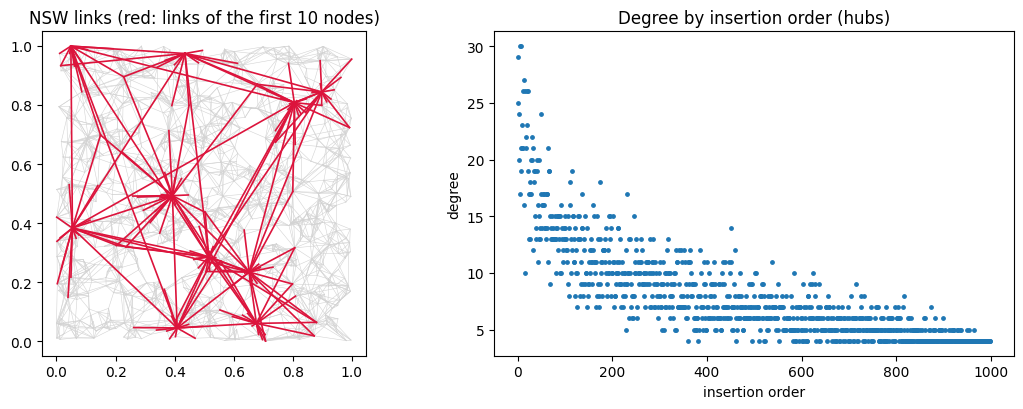

In [12]:
rng = np.random.default_rng(5)
Xn1 = rng.random((1000, 2))
nsw1k = NSW(M=4, ef_construction=20).build(Xn1)
link_len = [np.mean([l2(Xn1[i], Xn1[j]) for j in nsw1k.adj[i]]) for i in range(len(Xn1))]
degree = [len(nsw1k.adj[i]) for i in range(len(Xn1))]
print(f"{'inserted':>14} | mean link length | mean degree")
for a, b in [(0, 10), (10, 100), (100, 1000)]:
    print(f"{f'{a}-{b - 1}':>14} | {np.mean(link_len[a:b]):16.3f} | {np.mean(degree[a:b]):11.1f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for i in range(len(Xn1)):
    for j in nsw1k.adj[i]:
        if j > i: axes[0].plot(*Xn1[[i, j]].T, c="crimson" if i < 10 else "lightgray", lw=1.2 if i < 10 else .4, zorder=2 if i < 10 else 1)
axes[0].set_title("NSW links (red: links of the first 10 nodes)"); axes[0].set_aspect("equal")
axes[1].scatter(range(len(Xn1)), degree, s=6); axes[1].set_xlabel("insertion order"); axes[1].set_ylabel("degree"); axes[1].set_title("Degree by insertion order (hubs)")
plt.tight_layout(); plt.show()

## 1.8 Hierarchical NSW (HNSW)
HNSW (Malkov & Yashunin, 2016/2018) stacks several NSW graphs, like a **skip list**:

```
layer 2 :   o-----------------o                  (very few nodes, long links)
layer 1 :   o-------o---------o-------o          (more nodes)
layer 0 :   o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o      (ALL nodes, short links)
```

* Every point is stored in layer 0. With probability decaying exponentially it is also stored in higher layers: its maximum layer is $\ell=\lfloor -\ln(\text{U}(0,1))\cdot m_L\rfloor$ with $m_L=1/\ln M$. So a fraction $\approx 1/M$ of the nodes reaches layer 1, $1/M^2$ layer 2, …
* **Search:** start at the global entry point in the top layer, run a greedy search (`ef=1`) there, use the result as the entry point of the layer below, … until layer 0, where a beam search with `ef = efSearch` is run and the best $k$ nodes are returned.
* **Insertion:** draw the level $\ell$ of the new point, descend greedily through the layers above $\ell$, then in each layer $\le \ell$ find `efConstruction` candidates, choose up to $M$ of them as neighbours (using a heuristic that prefers *diverse* directions instead of just the closest ones), and add bidirectional links. Layer 0 allows up to $2M$ links per node.

**Why it works:** upper layers play the role of "highways" (large jumps), lower layers refine locally. Search cost grows roughly as $O(\log n)$, while memory is $O(n\cdot M)$ links on top of the vectors.

Let us verify the idea with a **two-layer toy HNSW**: take a random 10 % sample as the upper layer (with its own graph), search it greedily to get an entry point, then continue in the full graph.

In [13]:
# Toy 2-layer hierarchy on the same 2-D data
rng = np.random.default_rng(4)
top_ids = np.sort(rng.choice(len(X), size=len(X) // 10, replace=False))   # upper layer members (10%)
X_top = X[top_ids]
adj_top = knn_graph(X_top, k=4)                                           # graph of the upper layer

queries = rng.random((300, 2)); true1 = [int(np.argmin(np.linalg.norm(X - q, axis=1))) for q in queries]

def two_layer_search(q, ef=1):
    # 1) greedy in the upper layer from a random node, 2) continue in layer 0 from the node found
    f_top, _, nd_top = greedy_search(adj_top, X_top, q, int(rng.integers(len(X_top))))
    ids, nd0 = beam_search(adj, X, q, int(top_ids[f_top]), ef)
    return ids[0], nd_top + nd0

for name, fn in [("flat graph, random entry", lambda q: (lambda r: (r[0][0], r[1]))(beam_search(adj, X, q, int(rng.integers(len(X))), 1))),
                 ("2 layers (toy HNSW)      ", two_layer_search)]:
    hit = cost = 0
    for q, t in zip(queries, true1):
        found, nd = fn(q); hit += found == t; cost += nd
    print(f"{name}: 1-NN accuracy={hit/len(queries):.2f}  avg distance computations={cost/len(queries):.1f}")
# The hierarchy gives a better entry point, so the final layer-0 search needs fewer hops and is more accurate.

flat graph, random entry: 1-NN accuracy=0.28  avg distance computations=19.3
2 layers (toy HNSW)      : 1-NN accuracy=0.81  avg distance computations=30.4


### 1.8.1 Our HNSW at scale, validated against brute force
The toy above glued two graphs together by hand. Now use the real algorithm from the library (random levels, `efConstruction`, degree limits). We check three things on random data:
1. the levels follow the geometric law (about $1/M$ of the nodes per extra layer);
2. recall@10 and the number of distance computations, compared with NSW, as `ef` grows;
3. the effect of dimension (2-D versus 20-D), which is where Lab 09's trees failed.

Our Python code is slow to build (a few seconds for 2000 points); that is why real systems use C++ libraries such as NMSLIB (Part 3).

In [14]:
rng = np.random.default_rng(0)
rows = []
for d in [2, 20]:
    Xs, Qs = rng.random((2000, d)), rng.random((100, d))
    gt = [np.argsort(np.linalg.norm(Xs - q, axis=1))[:10] for q in Qs]
    hn = HNSW(M=8, ef_construction=40, seed=0).build(Xs)
    nw = NSW(M=8, ef_construction=40).build(Xs)
    if d == 2:
        print("HNSW nodes per top level (M = 8):", dict(enumerate(np.bincount(list(hn.level.values())).tolist())))
    for ef in [10, 20, 50]:
        for name, ix in [("HNSW", hn), ("NSW", nw)]:
            rec = cost = 0
            for q, t in zip(Qs, gt):
                ids, _, nd = ix.search(q, 10, ef)
                rec += len(set(ids) & set(t)) / 10; cost += nd
            rows.append({"dim": d, "index": name, "ef": ef, "recall@10": rec / len(Qs), "distances / query": cost / len(Qs)})
import pandas as pd
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("brute force needs 2000 distances per query")

HNSW nodes per top level (M = 8): {0: 1755, 1: 215, 2: 28, 3: 2}
 dim index  ef  recall@10  distances / query
   2  HNSW  10      0.994              67.99
   2   NSW  10      1.000             136.64
   2  HNSW  20      1.000              83.80
   2   NSW  20      1.000             151.46
   2  HNSW  50      1.000             127.95
   2   NSW  50      1.000             192.20
  20  HNSW  10      0.708             162.23
  20   NSW  10      0.785             253.74
  20  HNSW  20      0.849             238.99
  20   NSW  20      0.907             356.40
  20  HNSW  50      0.965             442.58
  20   NSW  50      0.983             621.88
brute force needs 2000 distances per query


**Typical result** (seed 0): in 2-D both graphs reach recall ≈ 1.0 with about 70–150 distance computations instead of 2000. In 20-D the same `ef` gives lower recall (≈ 0.7–0.8 at `ef = 10`, ≈ 0.97 at `ef = 50`): the problem gets harder with dimension, but unlike the trees the graph keeps working, and `ef` lets you buy recall back. HNSW needs fewer distance computations than NSW for the same `ef`; NSW's higher recall comes from its unlimited degree (more links per node, more work).

### 1.8.2 Why the *heuristic* neighbour selection matters
Simple selection links a new point to its `M` closest candidates. On clustered data those are all in the same cluster, so clusters become islands that the search cannot leave. The heuristic (Algorithm 4) keeps a candidate only if it is closer to the new point than to every neighbour already chosen, which spreads the links in different directions and keeps bridges between clusters.

In [15]:
rng = np.random.default_rng(1)
centers = rng.random((10, 2)) * 10
Xc = np.vstack([c + rng.normal(0, .15, (200, 2)) for c in centers])
Qc = np.vstack([c + rng.normal(0, .15, (10, 2)) for c in centers])
gtc = [np.argsort(np.linalg.norm(Xc - q, axis=1))[:10] for q in Qc]
for heur in [False, True]:
    h = HNSW(M=4, ef_construction=20, seed=1, heuristic=heur).build(Xc)
    for ef in [10, 20]:
        rec = np.mean([len(set(h.search(q, 10, ef)[0]) & set(t)) / 10 for q, t in zip(Qc, gtc)])
        print(f"heuristic={str(heur):5}  ef={ef:>2}  recall@10 = {rec:.3f}")

heuristic=False  ef=10  recall@10 = 0.799
heuristic=False  ef=20  recall@10 = 0.816
heuristic=True   ef=10  recall@10 = 0.978
heuristic=True   ef=20  recall@10 = 0.983


## 1.9 HNSW parameters (as used in NMSLIB)

| Parameter | Used when | Meaning | Larger value ⇒ |
|---|---|---|---|
| `M` | build | max. number of neighbours linked per node (layer 0 keeps up to `2M`) | higher recall, **more memory**, slower build and search |
| `efConstruction` | build | size of the candidate list while inserting a point | better graph quality (recall↑), **much slower build** |
| `efSearch` (`ef`) | query | size of the candidate list at layer 0 during search | recall↑, **query time↑** (must be ≥ k) |
| `post` | build | post-processing of the graph: `0` none, `1` and `2` add extra processing (2 = more) | slightly better graph, slower build |
| `indexThreadQty` | build | threads used to build | faster build (results can differ slightly between runs) |

**Rules of thumb**
* `M` between 12 and 48 works for most data; small `M` suits low-dimensional / easy data, large `M` high-dimensional / high-recall requirements.
* `efConstruction` is usually 100–500; choose it so that building time is acceptable, because it is paid once.
* `efSearch` is the **run-time knob**: you can change it without rebuilding the index, to move along the recall ↔ latency curve.

**Costs summary**

| Method | Build | Query | Memory | Exact? |
|---|---|---|---|---|
| Brute force | none | $O(nd)$ | $O(nd)$ | yes |
| HNSW | $O(n\log n)$ (heavy constant) | $\approx O(\log n)$ | $O(nd + nM)$ | no (recall < 1) |

## 1.10 Libraries
**NMSLIB** (Non-Metric Space Library) implements HNSW (`method='hnsw'`) and a brute-force baseline (`method='brute_force'`) behind a common Python API: `init → addDataPointBatch → createIndex → knnQuery / knnQueryBatch`. Alternatives with the same algorithm: `hnswlib`, FAISS (`IndexHNSWFlat`), Lucene/Elasticsearch, Qdrant, Weaviate, pgvector.

## 1.11 Where do the vectors come from?
* **Word embeddings** (word2vec, GloVe, fastText) give one vector per word. A sentence vector can be the **average of its word vectors** (this is what spaCy's `Doc.vector` and fastText's `get_sentence_vector` do, roughly).
* **Sentence/Transformer embeddings** (SBERT, E5, …) are better for retrieval but slower to compute.

In this lab we embed Jeopardy! quiz clues with 300-dimensional vectors and index them.

## 1.12 Trees and graphs side by side

| | Trees (Lab 09) | Graphs (this lab) |
|---|---|---|
| Idea | partition the space, prune regions | link near vectors, walk towards the query |
| Search cost driver | how many regions survive the pruning test | how many nodes the beam search visits (`ef`) |
| High dimension | pruning fails, exact trees become brute force | still works; recall controlled by `ef`, `M` |
| Exact? | KD / Ball / VP yes, Annoy no | no (recall < 1, tunable) |
| Updates | Annoy: rebuild; sklearn trees: rebuild | HNSW: points can be inserted at any time |
| Memory | vectors + tree nodes | vectors + about `n · 2M` links |

Part 7 measures this table on the Jeopardy embeddings.